In [1]:

!pip install -q kaggle opencv-python-headless matplotlib numpy pandas


In [2]:

from google.colab import files

uploaded = files.upload()


Saving archive (5).zip to archive (5).zip


In [3]:

import os
import zipfile

zip_path = "/content/archive (5).zip"
extract_path = "/content/license_plate_dataset"

with zipfile.ZipFile(zip_path, "r") as z:
    print("Files in ZIP:", len(z.namelist()))
    z.extractall(extract_path)

print("\nExtraction complete. Sample paths:")
for root, dirs, files in os.walk(extract_path):
    if files:
        print(root, "→", files[:5])


Files in ZIP: 3396

Extraction complete. Sample paths:
/content/license_plate_dataset/google_images → ['a2d49f53-4121-4627-b5d9-069f8b2f8490___840256171_1_1080x720_maruti-suzuki-wagon-r-vxi-with-abs-minor-2014-petrol-erode.jpg.jpeg', '6ed8b283-5cf5-4727-9969-c79f70f47e80___2-cars-same-numbers.jpg.jpeg', 'car-wbs-MH06AW8929_00001.xml', 'car-wbs-KA03MG2784_00000.xml', 'car-wbs-HR696969_00000.jpeg']
/content/license_plate_dataset/State-wise_OLX/SK → ['SK1.jpg', 'SK9.xml', 'SK1.xml', 'SK7.jpg', 'SK13.jpg']
/content/license_plate_dataset/State-wise_OLX/TS → ['TS14.xml', 'TS5.jpg', 'TS3.xml', 'TS4.xml', 'TS7.jpg']
/content/license_plate_dataset/State-wise_OLX/GA → ['GA11.jpg', 'GA8.xml', 'GA3.jpg', 'GA6.jpg', 'GA10.jpg']
/content/license_plate_dataset/State-wise_OLX/TN → ['TN8.jpg', 'TN5.xml', 'TN1.xml', 'TN6.jpg', 'TN3.xml']
/content/license_plate_dataset/State-wise_OLX/KL → ['KL9.xml', 'KL8.jpg', 'KL19.jpg', 'KL7.jpg', 'KL11.xml']
/content/license_plate_dataset/State-wise_OLX/ML → ['ML39.j

XML annotations found: 1697
Sample image: /content/license_plate_dataset/google_images/car-wbs-MH06AW8929_00001.jpeg
Sample annotation: /content/license_plate_dataset/google_images/car-wbs-MH06AW8929_00001.xml
Annotation details:
<annotation>
	<folder>image</folder>
	<filename>car-wbs-MH06AW8929_00001.jpeg</filename>
	<path>C:\Users\Siri\Desktop\BARC_ki_padhai\Project\Indian_ANPR_090921\v3andv4\image\car-wbs-MH06AW8929_00001.jpeg</path>
	<source>
		<database>Unknown</database>
	</source>
	<size>
		<width>580</width>
		<height>251</height>
		<depth>3</depth>
	</size>
	<segmented>0</segmented>
	<object>
		<name>MH06AW8929</name>
		<pose>Unspecified</pose>
		<truncated>0</truncated>
		<difficult>0</difficult>
		<bndbox>
			<xmin>192</xmin>
			<ymin>131</ymin>
			<xmax>364</xmax>
			<ymax>179</ymax>
		</bndbox>
	</object>
</annotation>


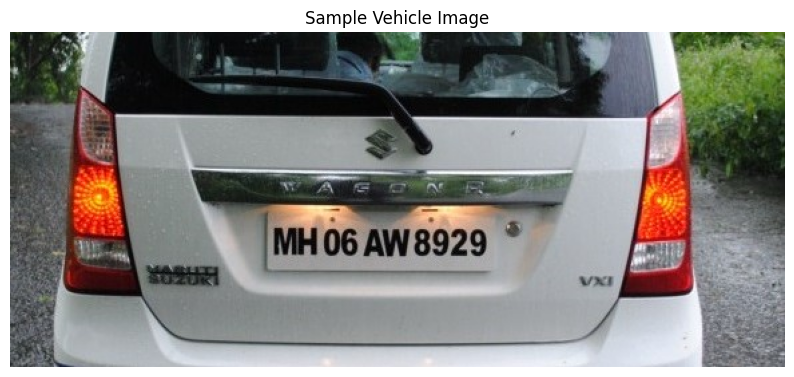

In [4]:

!pip install -q ultralytics easyocr

import os, glob, random, cv2
import matplotlib.pyplot as plt
import xml.etree.ElementTree as ET

BASE = "/content/license_plate_dataset"
xml_files = glob.glob(BASE + "/**/*.xml", recursive=True)

print("XML annotations found:", len(xml_files))

# Find an annotation whose matching image exists
sample_xml = None
sample_img = None

for x in xml_files:
    root = ET.parse(x).getroot()
    filename = root.findtext("filename")
    candidates = []
    if filename:
        candidates.append(os.path.join(os.path.dirname(x), filename))
    candidates += [
        os.path.splitext(x)[0] + ext
        for ext in [".jpg", ".jpeg", ".png", ".JPG", ".JPEG"]
    ]
    for p in candidates:
        if os.path.isfile(p):
            sample_xml, sample_img = x, p
            break
    if sample_img:
        break

if sample_img:
    print("Sample image:", sample_img)
    print("Sample annotation:", sample_xml)
    root = ET.parse(sample_xml).getroot()
    print("Annotation details:")
    print(ET.tostring(root, encoding="unicode")[:1800])

    image = cv2.cvtColor(cv2.imread(sample_img), cv2.COLOR_BGR2RGB)
    plt.figure(figsize=(10, 6))
    plt.imshow(image)
    plt.title("Sample Vehicle Image")
    plt.axis("off")
    plt.show()
else:
    print("No matching image/XML pair found.")


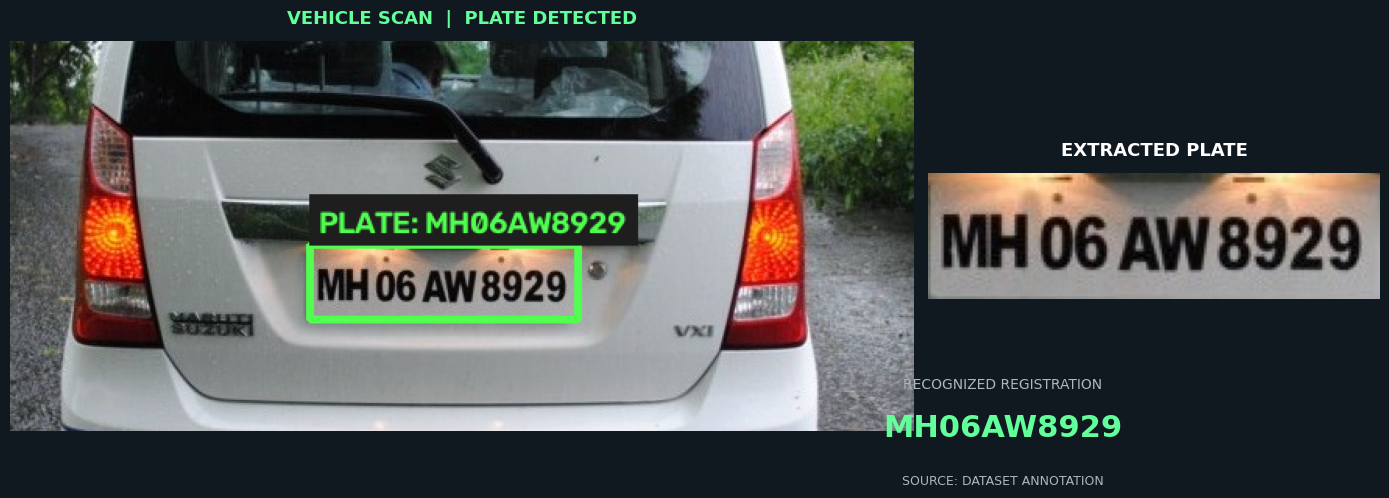

In [6]:

import cv2
import xml.etree.ElementTree as ET
import matplotlib.pyplot as plt
from PIL import Image
import numpy as np

# Load annotation and image
root = ET.parse(sample_xml).getroot()
image = cv2.imread(sample_img)
plate_text = "Unknown"
box_coords = None

for obj in root.findall("object"):
    plate_text = obj.findtext("name", "Unknown")
    box = obj.find("bndbox")
    x1 = int(float(box.findtext("xmin")))
    y1 = int(float(box.findtext("ymin")))
    x2 = int(float(box.findtext("xmax")))
    y2 = int(float(box.findtext("ymax")))
    box_coords = (x1, y1, x2, y2)

    # Neon-green detection box
    cv2.rectangle(image, (x1, y1), (x2, y2), (80, 255, 80), 3)

    # Label background
    label = f"PLATE: {plate_text}"
    (tw, th), _ = cv2.getTextSize(
        label, cv2.FONT_HERSHEY_SIMPLEX, 0.65, 2
    )
    top = max(0, y1 - th - 14)
    cv2.rectangle(image, (x1, top), (x1 + tw + 12, y1), (30, 30, 30), -1)
    cv2.putText(
        image, label, (x1 + 6, y1 - 7),
        cv2.FONT_HERSHEY_SIMPLEX, 0.65, (80, 255, 80), 2
    )

# Crop the annotated plate
x1, y1, x2, y2 = box_coords
crop = cv2.cvtColor(
    cv2.imread(sample_img)[y1:y2, x1:x2], cv2.COLOR_BGR2RGB
)
image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

# Dashboard-style display
fig, ax = plt.subplots(
    1, 2, figsize=(14, 6),
    facecolor="#101820",
    gridspec_kw={"width_ratios": [2, 1]}
)

for a in ax:
    a.set_facecolor("#101820")
    a.axis("off")

ax[0].imshow(image_rgb)
ax[0].set_title(
    "VEHICLE SCAN  |  PLATE DETECTED",
    color="#62FF9B", fontsize=13, fontweight="bold", pad=12
)

ax[1].imshow(crop)
ax[1].set_title("EXTRACTED PLATE", color="white",
                fontsize=13, fontweight="bold", pad=12)

fig.text(0.72, 0.24, "RECOGNIZED REGISTRATION",
         color="#AAB8C2", fontsize=10, ha="center")
fig.text(0.72, 0.16, plate_text,
         color="#62FF9B", fontsize=22, fontweight="bold", ha="center")
fig.text(0.72, 0.08, "SOURCE: DATASET ANNOTATION",
         color="#AAB8C2", fontsize=9, ha="center")

plt.tight_layout(rect=[0, 0.05, 1, 0.94])
plt.show()
